### TP : Prétraitement d’un Dataset en Machine Learning

### EL KARMAOUI Nouhaila

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler


### Partie 1 : Introduction au Dataset

In [46]:
df = pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [47]:
df.shape

(891, 12)

In [5]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [6]:
df.select_dtypes(include=np.number).columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

In [7]:
df.select_dtypes(include="object").columns

Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], dtype='object')

In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### Séparation des données

In [13]:
X = df.drop("Survived", axis=1)
y = df["Survived"]

# Séparation des données
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [14]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 11)
X_test: (179, 11)
y_train: (712,)
y_test: (179,)


### Partie 2 : Nettoyage des Données

### 1. Gestion des valeurs manquantes :

In [15]:
# Vérifier les valeurs manquantes dans Training
print("Training:")
print(X_train.isnull().sum())

# Vérifier les valeurs manquantes dans Testing
print("\nTesting:")
print(X_test.isnull().sum())

Training:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age            137
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          552
Embarked         2
dtype: int64

Testing:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             40
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          135
Embarked         0
dtype: int64


In [16]:
# Calculer le pourcentage des valeurs manquantes
missing_percent = X_train.isnull().mean() * 100

# Identifier les colonnes avec plus de 40% de valeurs manquantes
cols_to_drop = missing_percent[missing_percent > 40].index

# Supprimer ces colonnes
X_train = X_train.drop(columns=cols_to_drop)
X_test = X_test.drop(columns=cols_to_drop)

print("Colonnes supprimées:", list(cols_to_drop))

Colonnes supprimées: ['Cabin']


In [18]:
# Création de l'imputer
age_imputer = SimpleImputer(strategy="median")

In [19]:
# Apprendre la mediane sur Training
X_train[["Age"]] = age_imputer.fit_transform(
    X_train[["Age"]]
)

# Appliquer la meme mediane sur Testing
X_test[["Age"]] = age_imputer.transform(
    X_test[["Age"]]
)

In [20]:
# Creation de l'imputer pour Embarked
embarked_imputer = SimpleImputer(strategy="most_frequent")

# Traitement de Training
X_train[["Embarked"]] = embarked_imputer.fit_transform(
    X_train[["Embarked"]]
)

# Traitement de Testing
X_test[["Embarked"]] = embarked_imputer.transform(
    X_test[["Embarked"]]
)

In [21]:
print("Missing values in Training:")
print(X_train.isnull().sum())

print("\nMissing values in Testing:")
print(X_test.isnull().sum())

Missing values in Training:
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Missing values in Testing:
PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


## 2. Gestion des valeurs aberrantes :

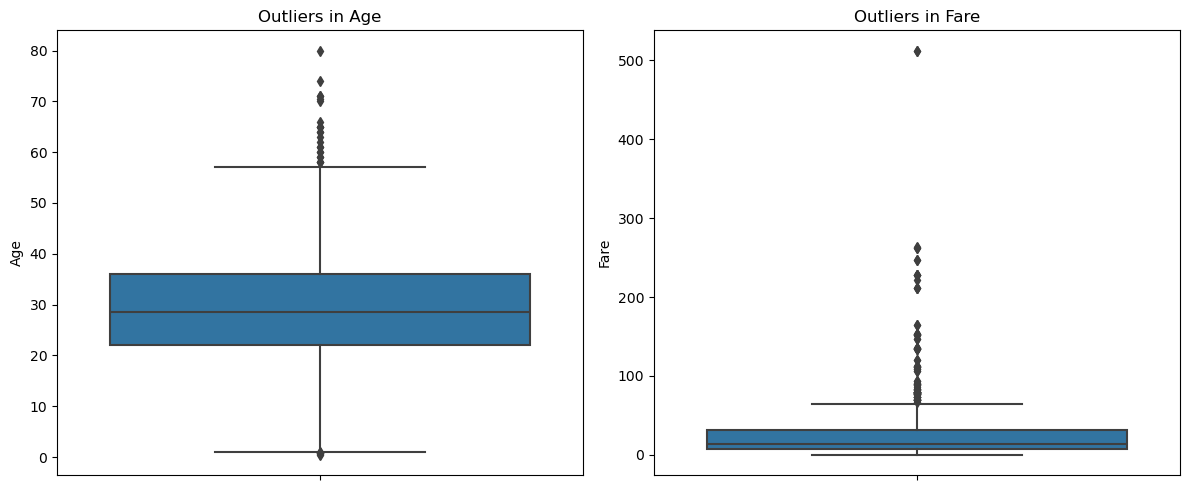

In [22]:
# Visualisation des valeurs aberrantes

plt.figure(figsize=(12, 5))

# Boxplot de Age
plt.subplot(1, 2, 1)
sns.boxplot(y=X_train["Age"])
plt.title("Outliers in Age")

# Boxplot de Fare
plt.subplot(1, 2, 2)
sns.boxplot(y=X_train["Fare"])
plt.title("Outliers in Fare")

plt.tight_layout()
plt.show()

In [23]:
# Detection des valeurs aberrantes avec IQR

for col in ["Age", "Fare"]:

    Q1 = X_train[col].quantile(0.25)

    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR

    upper = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[col] < lower) |
        (X_train[col] > upper)
    ]

    print("Variable:", col)
    print("Nombre de valeurs aberrantes:", len(outliers))
    print("Lower:", lower)
    print("Upper:", upper)
    print("------------------------")

Variable: Age
Nombre de valeurs aberrantes: 29
Lower: 1.0
Upper: 57.0
------------------------
Variable: Fare
Nombre de valeurs aberrantes: 91
Lower: -26.7605
Upper: 65.6563
------------------------


In [24]:
# Remplacement des outliers par la mediane

for col in ["Age", "Fare"]:

    # Calcul des quartiles sur Training
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    # Calcul de IQR
    IQR = Q3 - Q1

    # Calcul des limites
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Calcul de la mediane
    median = X_train[col].median()

    # Remplacer les outliers dans Training
    X_train[col] = X_train[col].mask(
        (X_train[col] < lower) | (X_train[col] > upper),
        median
    )

    # Remplacer les outliers dans Testing
    X_test[col] = X_test[col].mask(
        (X_test[col] < lower) | (X_test[col] > upper),
        median
    )

print("Outliers replaced successfully!")

Outliers replaced successfully!


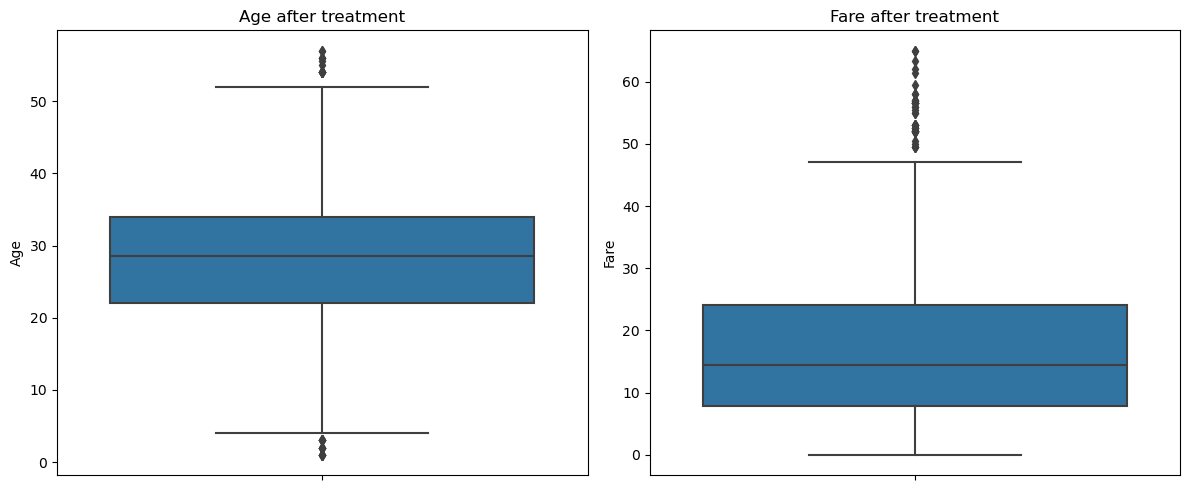

In [25]:
# Visualisation apres traitement

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=X_train["Age"])
plt.title("Age after treatment")

plt.subplot(1, 2, 2)
sns.boxplot(y=X_train["Fare"])
plt.title("Fare after treatment")

plt.tight_layout()
plt.show()

### Partie 3 : Transformation des Données

### 1. Encodage des variables catégorielles :

In [26]:
# Supprimer les colonnes non necessaires
X_train = X_train.drop(
    columns=["PassengerId", "Name", "Ticket"],
    errors="ignore"
)

X_test = X_test.drop(
    columns=["PassengerId", "Name", "Ticket"],
    errors="ignore"
)

In [27]:
# One-Hot Encoding des variables categorielles
X_train_encoded = pd.get_dummies(
    X_train,
    columns=["Sex", "Embarked"],
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=["Sex", "Embarked"],
    dtype=int
)

# Aligner les colonnes de Training et Testing
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

In [29]:
X_train_encoded.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,3,28.5,0,0,56.4958,0,1,0,0,1
481,2,28.5,0,0,0.0000,0,1,0,0,1
527,1,28.5,0,0,14.4542,0,1,0,0,1
855,3,18.0,0,1,9.3500,1,0,0,0,1
801,2,31.0,1,1,26.2500,1,0,0,0,1


In [31]:
X_train_encoded["Pclass"].value_counts()

Pclass
3    391
1    171
2    150
Name: count, dtype: int64

### 2. Normalisation et Standardisation des données :

In [33]:

# Selection des variables numeriques
num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

# Creation du scaler
minmax_scaler = MinMaxScaler()

# Application sur Training
X_train_minmax = X_train_encoded.copy()

X_train_minmax[num_cols] = minmax_scaler.fit_transform(
    X_train_encoded[num_cols]
)

# Application sur Testing
X_test_minmax = X_test_encoded.copy()

X_test_minmax[num_cols] = minmax_scaler.transform(
    X_test_encoded[num_cols]
)

In [50]:
X_train_minmax[num_cols].head()

,Pclass,Age,SibSp,Parch,Fare
692,1.0,0.491071,0.000,0.000000,0.869166
481,0.5,0.491071,0.000,0.000000,0.000000
527,0.0,0.491071,0.000,0.000000,0.222372
855,1.0,0.303571,0.000,0.166667,0.143846
801,0.5,0.535714,0.125,0.166667,0.403846


In [35]:
# Creation du StandardScaler
standard_scaler = StandardScaler()

# Copie des donnees encodees
X_train_standard = X_train_encoded.copy()

# Application sur Training
X_train_standard[num_cols] = standard_scaler.fit_transform(
    X_train_encoded[num_cols]
)

# Application sur Testing
X_test_standard = X_test_encoded.copy()

X_test_standard[num_cols] = standard_scaler.transform(
    X_test_encoded[num_cols]
)

In [52]:
print("Application de Min-Max Scaling:")
print(X_train_minmax[num_cols].head())

print("\nMean after standardisation:")
print(X_train_standard[num_cols].mean())

print("\nStandard deviation:")
print(X_train_standard[num_cols].std())

Application de Min-Max Scaling:
     Pclass       Age  SibSp     Parch      Fare
692     1.0  0.491071  0.000  0.000000  0.869166
481     0.5  0.491071  0.000  0.000000  0.000000
527     0.0  0.491071  0.000  0.000000  0.222372
855     1.0  0.303571  0.000  0.166667  0.143846
801     0.5  0.535714  0.125  0.166667  0.403846

Mean after standardisation:
Pclass   -1.821265e-16
Age       1.746418e-17
SibSp    -5.613487e-18
Parch    -1.621674e-17
Fare      1.122697e-16
dtype: float64

Standard deviation:
Pclass    1.000703
Age       1.000703
SibSp     1.000703
Parch     1.000703
Fare      1.000703
dtype: float64


C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


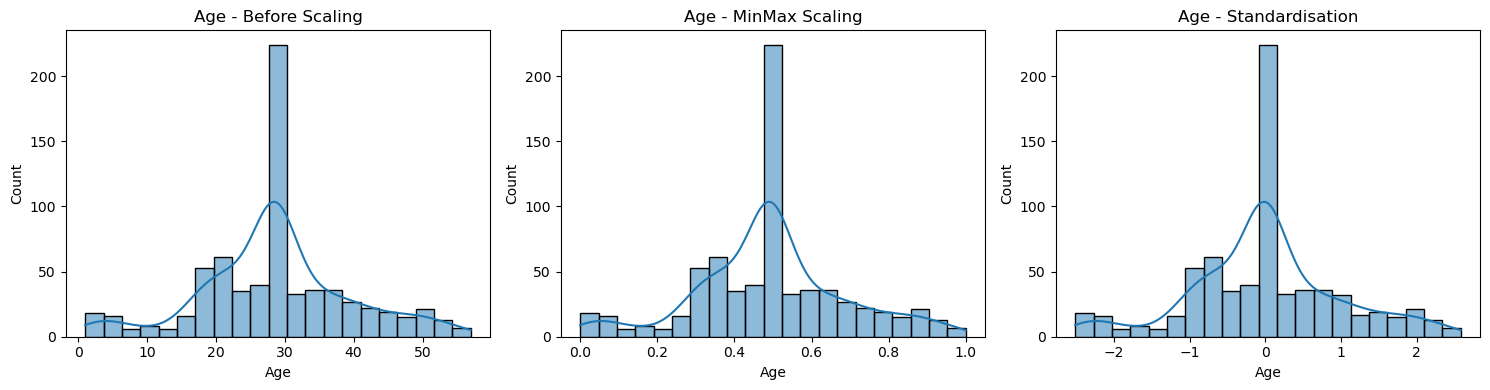

In [37]:
# Comparaison de Age
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(X_train_encoded["Age"], kde=True)
plt.title("Age - Before Scaling")

plt.subplot(1, 3, 2)
sns.histplot(X_train_minmax["Age"], kde=True)
plt.title("Age - MinMax Scaling")

plt.subplot(1, 3, 3)
sns.histplot(X_train_standard["Age"], kde=True)
plt.title("Age - Standardisation")

plt.tight_layout()
plt.show()

C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


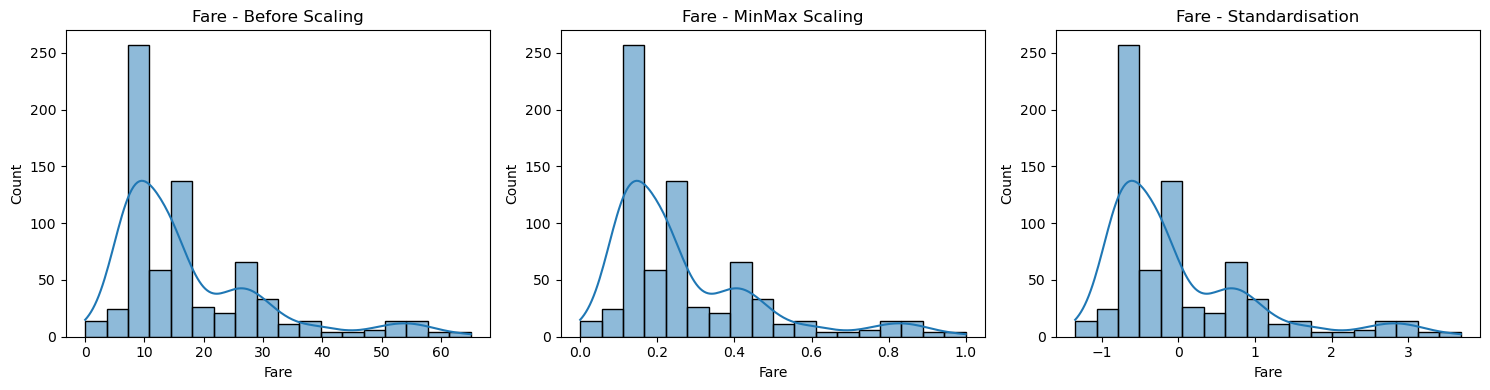

In [48]:
# Comparaison de Fare
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(X_train_encoded["Fare"], kde=True)
plt.title("Fare - Before Scaling")

plt.subplot(1, 3, 2)
sns.histplot(X_train_minmax["Fare"], kde=True)
plt.title("Fare - MinMax Scaling")

plt.subplot(1, 3, 3)
sns.histplot(X_train_standard["Fare"], kde=True)
plt.title("Fare - Standardisation")

plt.tight_layout()
plt.show()

### Partie 4 : Gestion des Données Déséquilibrées

### 1. Identification du déséquilibre des classes :

In [38]:
# Nombre d'observations dans chaque classe
print(y_train.value_counts())
# Pourcentage de chaque classe
print(y_train.value_counts(normalize=True) * 100)

Survived
0    439
1    273
Name: count, dtype: int64
Survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64


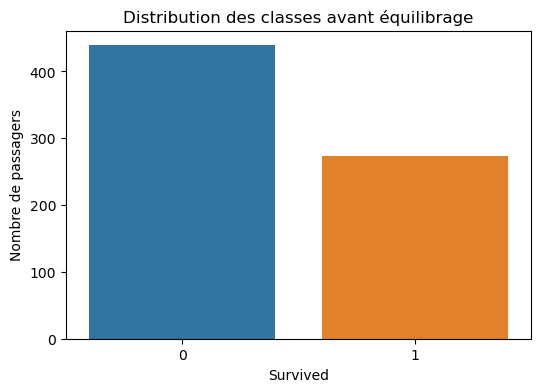

In [39]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title("Distribution des classes avant équilibrage")
plt.xlabel("Survived")
plt.ylabel("Nombre de passagers")
plt.show()

### 2. Gestion du déséquilibre :

In [40]:
# Création du sous-échantillonneur
under_sampler = RandomUnderSampler(random_state=42)

# Application sur les données d'entraînement
X_train_under, y_train_under = under_sampler.fit_resample(
    X_train_standard,
    y_train
)

# Vérification du résultat
print(y_train_under.value_counts())

Survived
0    273
1    273
Name: count, dtype: int64


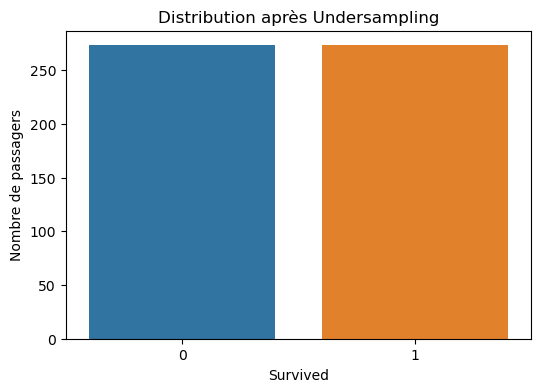

In [54]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y_train_under)

plt.title("Distribution après Undersampling")
plt.xlabel("Survived")
plt.ylabel("Nombre de passagers")

plt.show()

In [42]:
from imblearn.over_sampling import SMOTE

# Création de SMOTE
smote = SMOTE(random_state=42)

# Application sur les données d'entraînement
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_standard,
    y_train
)

# Vérification du résultat
print(y_train_smote.value_counts())

Survived
1    439
0    439
Name: count, dtype: int64


Survived
1    439
0    439
Name: count, dtype: int64


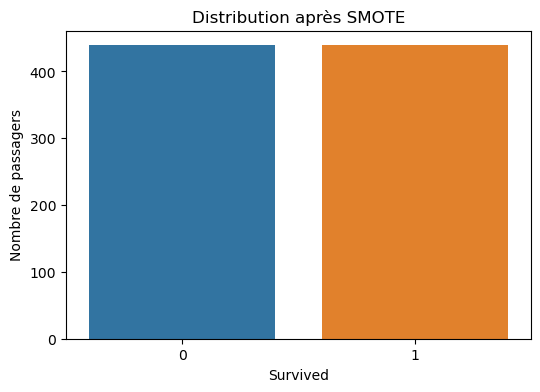

In [55]:
print(y_train_smote.value_counts())
plt.figure(figsize=(6, 4))

sns.countplot(x=y_train_smote)

plt.title("Distribution après SMOTE")
plt.xlabel("Survived")
plt.ylabel("Nombre de passagers")

plt.show()

In [44]:
print("Avant équilibrage :")
print(y_train.value_counts())

print("\nAprès Undersampling :")
print(y_train_under.value_counts())

print("\nAprès SMOTE :")
print(y_train_smote.value_counts())

Avant équilibrage :
Survived
0    439
1    273
Name: count, dtype: int64

Après Undersampling :
Survived
0    273
1    273
Name: count, dtype: int64

Après SMOTE :
Survived
1    439
0    439
Name: count, dtype: int64


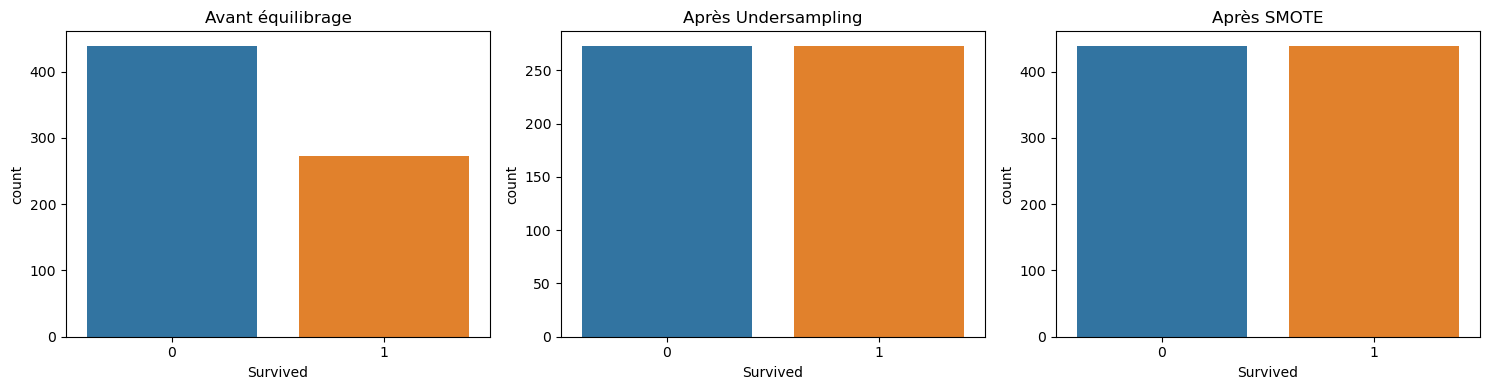

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Avant équilibrage")

sns.countplot(x=y_train_under, ax=axes[1])
axes[1].set_title("Après Undersampling")

sns.countplot(x=y_train_smote, ax=axes[2])
axes[2].set_title("Après SMOTE")

plt.tight_layout()
plt.show()